In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.patches import Circle
from astropy.io import fits
import pickle
from time import time

In [5]:
from aperture_class import AperturePhotometry

In [6]:

target_star = AperturePhotometry()
target_star.get_observatory_coordinates()

print("Numero di frame science:", target_star.science_size)
print("Primi 5 frame:", target_star.science_list[:5])

11.5689993 45.8485832 1376.2 test
Numero di frame science: 2611
Primi 5 frame: ['AF605681.fits' 'AF605682.fits' 'AF605683.fits' 'AF605684.fits'
 'AF605685.fits']


In [4]:

# full_science_list = target_star.science_list.copy()

# target_star.science_list = full_science_list[1100:1110]
# target_star.science_size = len(target_star.science_list)

# target_star.provide_aperture_parameters(15, 25, 10, 71.40, 102.14)

# target_star.aperture_photometry()

# print("Flussi calcolati (primi 10):", target_star.aperture)
# print("Centroidi X raffinati:", target_star.x_refined)
# print("Centroidi Y raffinati:", target_star.y_refined)
# print("BJD_TDB calcolati:", target_star.bjd_tdb[:3])

In [5]:
t0 = time()

target_star = AperturePhotometry()

target_star.provide_aperture_parameters(15, 25, 10, 71.40, 102.14)
target_star.aperture_photometry()

t1 = time()
print(f"Tempo impiegato per la target star: {t1 - t0:.2f} secondi")

Tempo impiegato per la target star: 49.64 secondi


In [6]:
t0 = time()

reference_star = AperturePhotometry()

reference_star.provide_aperture_parameters(15, 25, 10, 205, 60)
reference_star.aperture_photometry()

t1 = time()
print(f"Tempo impiegato per la reference star: {t1 - t0:.2f} secondi")

Tempo impiegato per la reference star: 49.11 secondi


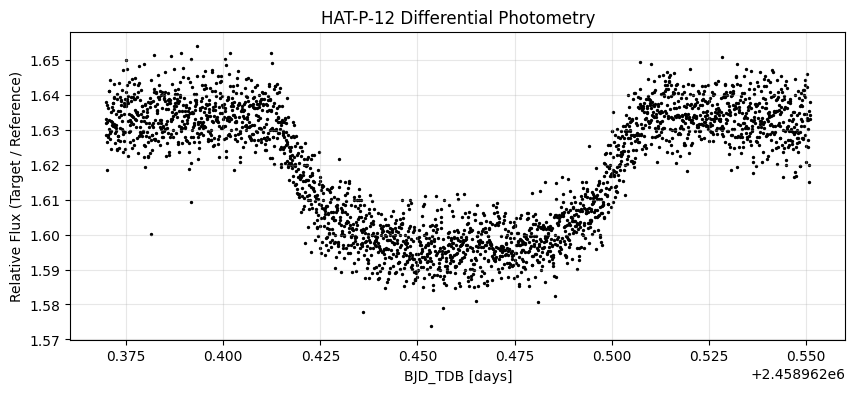

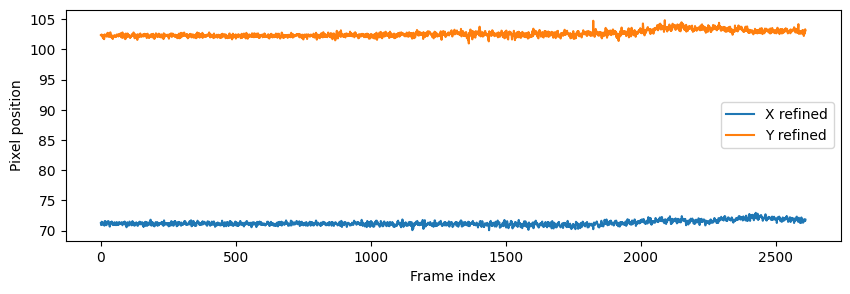

In [7]:

plt.figure(figsize=(10, 4))
plt.scatter(target_star.bjd_tdb.value, target_star.aperture / reference_star.aperture, s=2, color='black')
plt.xlabel('BJD_TDB [days]')
plt.ylabel('Relative Flux (Target / Reference)')
plt.title('HAT-P-12 Differential Photometry')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(target_star.x_refined, label='X refined')
plt.plot(target_star.y_refined, label='Y refined')
plt.xlabel('Frame index')
plt.ylabel('Pixel position')
plt.legend()
plt.show()